# U1 · Actividad anómala — Abdul Quispe Condori

**Proyecto:** CryptoPulse · Grupo 3 · Big Data UPeU 2026-2
**Pregunta central del equipo:** ¿Cómo puede un analista de riesgo anticipar, con 5 a 30 minutos de antelación, condiciones de riesgo en BTC y SOL: volatilidad alta, caídas fuertes, actividad anómala y desacople entre ambos activos?

**Dimensión U1 (batch, descriptiva/diagnóstica + predictiva):** ¿Cuándo hubo en BTC y SOL volumen u operaciones inusualmente altos (mayores que el 95 % de lo normal a esa misma hora del día), y qué probabilidad hay de que ocurra en los próximos 5 minutos?

- **Indicador:** % mensual de ventanas de 5 min sobre el P95 de volumen u operaciones por activo y hora; probabilidad estimada por un modelo de clasificación.
- **Decisión que habilita:** Anticipar momentos de liquidez extrema (noticias, liquidaciones) para revisar el mercado antes de operar.
- **Fuente batch:** Binance Public Data, velas de 1 minuto BTCUSDT y SOLUSDT, enero 2022 – septiembre 2026 (4 993 759 filas, ZIP con SHA256 verificado).
- **Relación con U2:** el mismo modelo y las mismas variables se aplican en vivo en Grafana, panel *Actividad anómala · probabilidad a 5 min*.

Este notebook corre de punta a punta sin intervención manual, sobre los datos reales que deja el pipeline (`scripts/entrenar_producto.ps1`).

## 0. Sesión Spark

In [1]:
import sys, json, math
sys.path.insert(0, "/opt")
from pathlib import Path
from operator import add
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, LongType, DecimalType, StringType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from cryptopulse.core import get_spark, ROOT, CLEAN, ML, FEATURES, TRAIN_END, VALIDATION_END
%matplotlib inline

spark = get_spark("u1-actividad_anomala", memory="3g", cores=4)
SALIDA = Path("/opt/u1-dimensiones/artifacts/actividad_anomala")
SALIDA.mkdir(parents=True, exist_ok=True)
print("Spark", spark.version, "| salida:", SALIDA)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/29 16:58:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | salida: /opt/u1-dimensiones/artifacts/actividad_anomala


## 1. Extracción con esquema explícito y evaluación perezosa

Se lee un archivo mensual crudo (`BTCUSDT-1m-2025-06.csv`) con `StructType`, sin dejar que Spark adivine tipos. Desde 2025 Binance publica los tiempos en microsegundos, por eso se dividen entre 1000.

In [2]:
ESQUEMA = StructType([StructField("open_time_raw", LongType())] +
    [StructField(c, DecimalType(28, 8)) for c in ["open", "high", "low", "close", "volume"]] +
    [StructField("close_time_raw", LongType()), StructField("quote_asset_volume", DecimalType(28, 8)),
     StructField("number_of_trades", LongType()), StructField("taker_buy_base_volume", DecimalType(28, 8)),
     StructField("taker_buy_quote_volume", DecimalType(28, 8)), StructField("ignore", StringType())])

crudo = spark.read.schema(ESQUEMA).option("mode", "FAILFAST").csv(str(ROOT / "s02-fundamentos/data/raw/BTCUSDT-1m-2025-06.csv"))
velas = (crudo
    .withColumn("open_ms", F.expr("open_time_raw DIV 1000"))
    .withColumn("event_time", F.timestamp_millis("open_ms"))
    .withColumn("rango_pct", 100 * (F.col("high") - F.col("low")) / F.col("open"))
    .withColumn("hora_utc", F.hour("event_time")))
velas.printSchema()

root
 |-- open_time_raw: long (nullable = true)
 |-- open: decimal(28,8) (nullable = true)
 |-- high: decimal(28,8) (nullable = true)
 |-- low: decimal(28,8) (nullable = true)
 |-- close: decimal(28,8) (nullable = true)
 |-- volume: decimal(28,8) (nullable = true)
 |-- close_time_raw: long (nullable = true)
 |-- quote_asset_volume: decimal(28,8) (nullable = true)
 |-- number_of_trades: long (nullable = true)
 |-- taker_buy_base_volume: decimal(28,8) (nullable = true)
 |-- taker_buy_quote_volume: decimal(28,8) (nullable = true)
 |-- ignore: string (nullable = true)
 |-- open_ms: long (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- rango_pct: decimal(38,6) (nullable = true)
 |-- hora_utc: integer (nullable = true)



In [3]:
# Transformaciones: Spark solo arma el plan, todavía no lee el archivo.
resumen_hora = (velas.filter(F.col("number_of_trades") > 0)
    .groupBy("hora_utc")
    .agg(F.count("*").alias("velas"), F.avg("rango_pct").alias("rango_medio_pct"),
         F.sum(F.col("quote_asset_volume").cast("double")).alias("usdt_negociado")))
resumen_hora.explain(True)

== Parsed Logical Plan ==
'Aggregate ['hora_utc], ['hora_utc, 'count(*) AS velas#17, 'avg('rango_pct) AS rango_medio_pct#18, 'sum(cast('quote_asset_volume as double)) AS usdt_negociado#19]
+- Filter (number_of_trades#8L > cast(0 as bigint))
   +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, rango_pct#15, hour(event_time#14, Some(UTC)) AS hora_utc#16]
      +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, (((high#2 - low#3) * cast(100 as decimal(3,0))) / open#1) AS rango_pct#15]
         +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume

In [4]:
# La acción (toPandas) es el momento en que Spark ejecuta el plan de verdad.
tabla_hora = resumen_hora.orderBy("hora_utc").toPandas()
tabla_hora.head(24)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,hora_utc,velas,rango_medio_pct,usdt_negociado
0,0,1800,0.0527457094,2.432809e+09
1,1,1800,0.0421954050,1.693839e+09
2,2,1800,0.0365408500,1.480464e+09
3,3,1800,0.0286373806,1.352975e+09
4,4,1800,0.0237177367,1.042498e+09
5,5,1800,0.0233594356,1.217157e+09
6,6,1800,0.0253182489,1.328792e+09
7,7,1800,0.0273947000,1.589556e+09
8,8,1800,0.0300616272,1.522422e+09
9,9,1800,0.0316711317,1.754350e+09


## 2. Calidad de datos: nulos y duplicados

**Decisión documentada:** no se imputan precios ni se fabrican velas. Una fila con un campo obligatorio nulo se descarta (en S03 va a cuarentena) y, si un mismo minuto aparece dos veces, se conserva una sola fila identificada con `row_number()`.

In [5]:
OBLIGATORIAS = ["open", "high", "low", "close", "volume", "quote_asset_volume", "number_of_trades"]
nulos = velas.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in OBLIGATORIAS])
nulos.show()

ventana = Window.partitionBy("open_ms").orderBy(F.col("number_of_trades").desc())
duplicados = velas.withColumn("fila", F.row_number().over(ventana)).filter("fila > 1").count()
limpio = velas.na.drop(subset=OBLIGATORIAS).dropDuplicates(["open_ms"])
filas_crudas, filas_limpias = velas.count(), limpio.count()
print(f"Duplicados por minuto: {duplicados} | filas crudas {filas_crudas} -> limpias {filas_limpias}")

s03 = json.loads((ROOT / "_runtime/s03.json").read_text(encoding="utf-8"))
print(f"Pipeline completo S03: {s03['input_rows']:,} filas -> {s03['clean_rows']:,} válidas, "
      f"{s03['invalid_rows']} en cuarentena, {s03['gaps']['gaps']} huecos ({s03['gaps']['missing_minutes']:.0f} min)")

+----+----+---+-----+------+------------------+----------------+
|open|high|low|close|volume|quote_asset_volume|number_of_trades|
+----+----+---+-----+------+------------------+----------------+
|   0|   0|  0|    0|     0|                 0|               0|
+----+----+---+-----+------+------------------+----------------+



Duplicados por minuto: 0 | filas crudas 43200 -> limpias 43200
Pipeline completo S03: 4,993,759 filas -> 4,993,757 válidas, 2 en cuarentena, 3 huecos (163 min)


## 3. Parquet particionado y verificación de ida y vuelta

El lago limpio está particionado por `symbol/year/month`. Se filtra la misma partición del archivo crudo y se confirma en el plan físico que Spark solo lee esa carpeta (`PartitionFilters`), y que el conteo coincide con el crudo limpio.

In [6]:
lago = spark.read.parquet(str(CLEAN))
particion = lago.filter((F.col("symbol") == "BTCUSDT") & (F.col("year") == 2025) & (F.col("month") == 6))
plan = particion._jdf.queryExecution().executedPlan().toString()
linea = next(l for l in plan.splitlines() if "PartitionFilters" in l)
print(linea[linea.index("PartitionFilters"):][:260])
assert "PartitionFilters: [" in plan and "BTCUSDT" in plan

filas_particion = particion.count()
print(f"Partición BTCUSDT 2025-06: {filas_particion} filas | crudo limpio: {filas_limpias}")
assert filas_particion == filas_limpias, "La lectura de vuelta no reconcilia con el crudo"

PartitionFilters: [isnotnull(symbol#256), isnotnull(year#257), isnotnull(month#258), (symbol#256 = BTCUSDT), (year#..., PushedFilters: [], ReadSchema: struct<open_time_raw:bigint,open:decimal(28,8),high:decimal(28,8),low:decimal(28,8),close:decimal...


Partición BTCUSDT 2025-06: 43200 filas | crudo limpio: 43200


## 4. Procesamiento con RDD

In [7]:
# Distribución del rango intravela (alto-bajo) en tramos de 0.1 %, con map/reduceByKey.
tramos = (limpio.select("rango_pct").rdd
    .map(lambda r: (min(int(float(r.rango_pct) * 10), 10), 1))
    .reduceByKey(add)
    .sortByKey()
    .collect())
for tramo, n in tramos:
    etiqueta = f">= {tramo/10:.1f} %" if tramo == 10 else f"{tramo/10:.1f}–{(tramo+1)/10:.1f} %"
    print(f"{etiqueta:>12}: {n:6d} velas")

   0.0–0.1 %:  39758 velas
   0.1–0.2 %:   2956 velas
   0.2–0.3 %:    389 velas
   0.3–0.4 %:     76 velas
   0.4–0.5 %:     15 velas
   0.5–0.6 %:      4 velas
   0.6–0.7 %:      1 velas
   0.7–0.8 %:      1 velas


## 5. Análisis descriptivo y diagnóstico (2022 – 2026)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


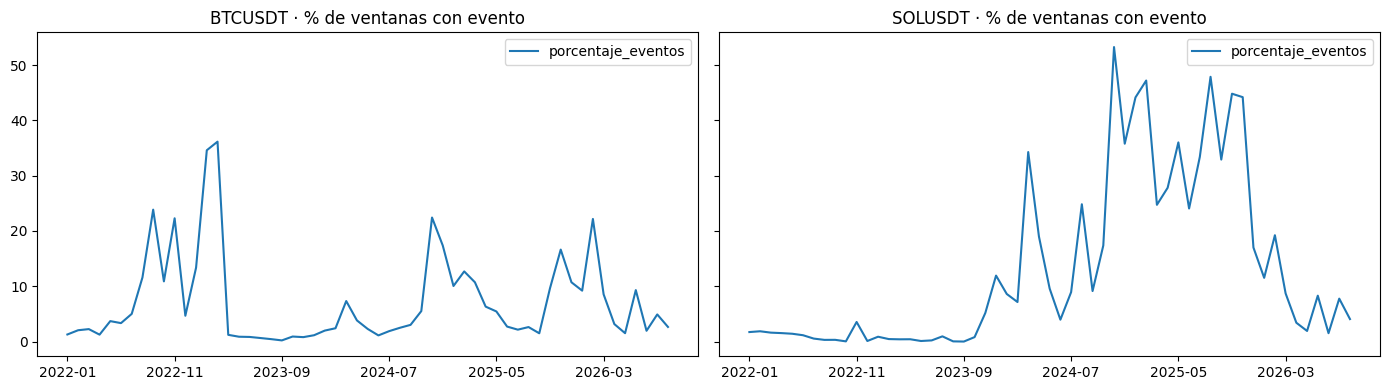

,symbol,mes,porcentaje_eventos
102,SOLUSDT,2026-04,3.402778
103,BTCUSDT,2026-04,3.159722
104,SOLUSDT,2026-05,1.915323
105,BTCUSDT,2026-05,1.512097
106,SOLUSDT,2026-06,8.298611
107,BTCUSDT,2026-06,9.305556
108,SOLUSDT,2026-07,1.512097
109,BTCUSDT,2026-07,1.948925
110,SOLUSDT,2026-08,7.762097
111,BTCUSDT,2026-08,4.905914


In [8]:
datos = (spark.read.parquet(str(ML / "model_dataset"))
    .withColumn("mes", F.date_format(F.timestamp_millis("open_ms"), "yyyy-MM"))
    .withColumn("hora_utc", F.hour(F.timestamp_millis("open_ms")))).cache()
mensual = datos.groupBy("symbol", "mes").agg((100 * F.avg("target_anomaly")).alias("porcentaje_eventos")).orderBy("mes").toPandas()
fig, ejes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for eje, (activo, grupo) in zip(ejes, mensual.groupby("symbol")):
    grupo.plot(x="mes", y="porcentaje_eventos", ax=eje, title=f"{activo} · % de ventanas con evento")
    eje.set_xlabel("")
plt.tight_layout(); plt.show()
mensual.groupby("symbol").tail(6)

**Diagnóstico:** ¿en qué horas UTC se concentra el fenómeno?

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


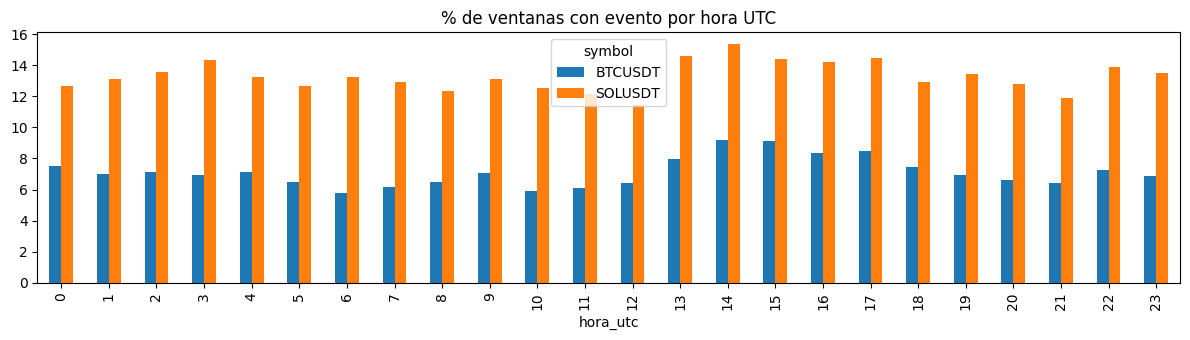

symbol
BTCUSDT    14
SOLUSDT    14
dtype: int32

In [9]:
diag = (datos.groupBy("symbol", "hora_utc").agg((100 * F.avg("target_anomaly")).alias("valor"))
    .orderBy("hora_utc").toPandas().pivot(index="hora_utc", columns="symbol", values="valor"))
diag.plot.bar(figsize=(12, 3.5), title="% de ventanas con evento por hora UTC"); plt.tight_layout(); plt.show()
diag.idxmax()

## 6. Modelo predictivo distribuido (Spark MLlib)

Partición temporal sin fuga de información: **entrenamiento 2022–2024**, **validación 2025**, **prueba enero–septiembre 2026**, con un embargo de 30 minutos entre tramos. El ganador se elige solo con validación; la prueba se usa una vez, al final.

In [10]:
base = datos.withColumnRenamed("target_anomaly", "label")
COLUMNAS = FEATURES

In [11]:
entrenamiento = base.filter(F.col("open_ms") + 1800000 < TRAIN_END).cache()
validacion = base.filter((F.col("open_ms") >= TRAIN_END) & (F.col("open_ms") + 1800000 < VALIDATION_END)).cache()
prueba = base.filter(F.col("open_ms") >= VALIDATION_END).cache()
print({"entrenamiento": entrenamiento.count(), "validacion": validacion.count(), "prueba": prueba.count()})

{'entrenamiento': 210392, 'validacion': 70076, 'prueba': 52412}


In [12]:
ensamblador = VectorAssembler(inputCols=COLUMNAS, outputCol="features")
escalador = StandardScaler(inputCol="features", outputCol="scaled", withMean=True, withStd=True)
CANDIDATOS = {
    "logistica_l2": [ensamblador, escalador, LogisticRegression(featuresCol="scaled", regParam=0.01, maxIter=60)],
    "logistica_elasticnet": [ensamblador, escalador, LogisticRegression(featuresCol="scaled", regParam=0.05, elasticNetParam=0.5, maxIter=60)],
    "random_forest": [ensamblador, RandomForestClassifier(numTrees=30, maxDepth=6, minInstancesPerNode=30, seed=26)],
}
prevalencia = {r.symbol: r.p for r in entrenamiento.groupBy("symbol").agg(F.avg("label").alias("p")).collect()}
mapa_prevalencia = F.create_map(*[x for s, p in prevalencia.items() for x in (F.lit(s), F.lit(p))])

def con_probabilidad(df):
    return df.withColumn("p", vector_to_array("probability")[1])

def mejor_umbral(df):
    filas = df.select("p", "label").toPandas()
    mejor = (0.0, 0.5)
    for u in filas["p"].quantile([i / 100 for i in range(5, 100)]).unique():
        pred = filas["p"] >= u
        tp = int((pred & (filas.label == 1)).sum()); fp = int((pred & (filas.label == 0)).sum())
        fn = int((~pred & (filas.label == 1)).sum())
        f1 = 2 * tp / max(1, 2 * tp + fp + fn)
        mejor = max(mejor, (f1, float(u)))
    return mejor[1]

def evaluar(df, umbral):
    auc_roc = BinaryClassificationEvaluator(rawPredictionCol="p", metricName="areaUnderROC").evaluate(df)
    auc_pr = BinaryClassificationEvaluator(rawPredictionCol="p", metricName="areaUnderPR").evaluate(df)
    r = df.withColumn("pos", (F.col("p") >= umbral).cast("int")).agg(
        F.avg((F.col("p") - F.col("label")) ** 2).alias("brier"),
        F.sum(((F.col("pos") == 1) & (F.col("label") == 1)).cast("int")).alias("tp"),
        F.sum(((F.col("pos") == 1) & (F.col("label") == 0)).cast("int")).alias("fp"),
        F.sum(((F.col("pos") == 0) & (F.col("label") == 1)).cast("int")).alias("fn")).first()
    precision = r.tp / max(1, r.tp + r.fp); recall = r.tp / max(1, r.tp + r.fn)
    return {"auc_roc": float(auc_roc), "auc_pr": float(auc_pr), "brier": float(r.brier), "precision": precision,
            "recall": recall, "f1": 2 * precision * recall / max(1e-9, precision + recall), "umbral": umbral}

modelos, umbrales, resultados_val = {}, {}, {}
referencia_val = validacion.withColumn("p", mapa_prevalencia[F.col("symbol")])
resultados_val["referencia"] = evaluar(referencia_val, 0.5)
for nombre, etapas in CANDIDATOS.items():
    modelos[nombre] = Pipeline(stages=etapas).fit(entrenamiento)
    puntuado = con_probabilidad(modelos[nombre].transform(validacion)).cache()
    umbrales[nombre] = mejor_umbral(puntuado)
    resultados_val[nombre] = evaluar(puntuado, umbrales[nombre])
tabla_val = pd.DataFrame(resultados_val).T.sort_values("auc_pr", ascending=False)
ganador = max(CANDIDATOS, key=lambda n: resultados_val[n]["auc_pr"])
print("Referencia: prevalencia histórica por activo | ganador en validación (AUC-PR):", ganador)
tabla_val

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Referencia: prevalencia histórica por activo | ganador en validación (AUC-PR): logistica_l2


,auc_roc,auc_pr,brier,precision,recall,f1,umbral
logistica_l2,0.930047,0.820236,0.111666,0.701266,0.752730,0.726087,0.172223
random_forest,0.912990,0.790597,0.108820,0.697444,0.781233,0.736964,0.133610
logistica_elasticnet,0.827578,0.612878,0.160715,0.481744,0.651971,0.554078,0.103655
referencia,0.705834,0.340666,0.187907,0.000000,0.000000,0.000000,0.500000


Prueba 2026: AUC-PR logistica_l2 0.660 vs referencia 0.072


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


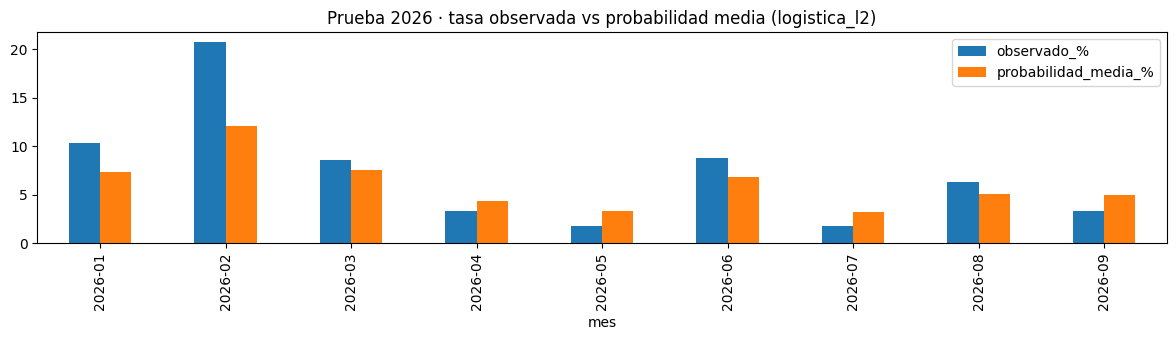

,auc_roc,auc_pr,brier,precision,recall,f1,umbral
logistica_l2,0.928701,0.659549,0.044073,0.570738,0.635433,0.60135,0.172223
referencia,0.507100,0.072276,0.065839,0.000000,0.000000,0.00000,0.500000


In [13]:
predicciones = con_probabilidad(modelos[ganador].transform(prueba)).cache()
resultados_test = {ganador: evaluar(predicciones, umbrales[ganador]),
                   "referencia": evaluar(prueba.withColumn("p", mapa_prevalencia[F.col("symbol")]), 0.5)}
print(f"Prueba 2026: AUC-PR {ganador} {resultados_test[ganador]['auc_pr']:.3f} vs referencia {resultados_test['referencia']['auc_pr']:.3f}")
mensual_test = (predicciones.withColumn("mes", F.date_format(F.timestamp_millis("open_ms"), "yyyy-MM"))
    .groupBy("mes").agg((100 * F.avg("label")).alias("observado_%"), (100 * F.avg("p")).alias("probabilidad_media_%"))
    .orderBy("mes").toPandas())
mensual_test.plot.bar(x="mes", figsize=(12, 3.5), title=f"Prueba 2026 · tasa observada vs probabilidad media ({ganador})")
plt.tight_layout(); plt.show()
pd.DataFrame(resultados_test).T

In [14]:
# Se guarda el modelo que ganó en validación (no el primero entrenado) y se comprueba que recarga.
ruta = str(SALIDA / "modelo_ganador")
modelos[ganador].write().overwrite().save(ruta)
recargado = PipelineModel.load(ruta)
print("Modelo guardado y recargado:", ruta, "| etapas:", [type(s).__name__ for s in recargado.stages])

Modelo guardado y recargado: /opt/u1-dimensiones/artifacts/actividad_anomala/modelo_ganador | etapas: ['VectorAssembler', 'StandardScalerModel', 'LogisticRegressionModel']


## 7. Registro de la verificación

In [15]:
verificacion = {"dimension": "actividad_anomala", "integrante": "Abdul Quispe Condori", "status": "PASS",
    "filas_crudas": filas_crudas, "filas_particion": filas_particion, "duplicados": duplicados,
    "modelo_ganador": ganador, "metricas_validacion": resultados_val, "metricas_prueba": resultados_test,
    "modelo_guardado": str(SALIDA / "modelo_ganador")}
(SALIDA / "verificacion_u1.json").write_text(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float))
spark.stop()

{
  "dimension": "actividad_anomala",
  "integrante": "Abdul Quispe Condori",
  "status": "PASS",
  "filas_crudas": 43200,
  "filas_particion": 43200,
  "duplicados": 0,
  "modelo_ganador": "logistica_l2",
  "metricas_validacion": {
    "referencia": {
      "auc_roc": 0.7058339200264119,
      "auc_pr": 0.3406661459619928,
      "brier": 0.187906838145522,
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "umbral": 0.5
    },
    "logistica_l2": {
      "auc_roc": 0.9300474118320283,
      "auc_pr": 0.8202355833278746,
      "brier": 0.1116657223905898,
      "precision": 0.7012656657153493,
      "recall": 0.75273042088439,
      "f1": 0.7260872358193615,
      "umbral": 0.17222262406712988
    },
    "logistica_elasticnet": {
      "auc_roc": 0.8275777921881511,
      "auc_pr": 0.6128784837216746,
      "brier": 0.16071493308050508,
      "precision": 0.48174392284223994,
      "recall": 0.6519712306872669,
      "f1": 0.5540777633142793,
      "umbral": 0.10365492

## 8. Las preguntas de mi dimensión y sus respuestas · Abdul

### Pregunta U1 (batch)
> ¿Cuándo hubo volumen u operaciones inusualmente altos (mayores que el 95 % de lo normal a esa misma hora del día), por mes y por hora?

**Respuesta.** Comparando cada ventana de 5 minutos con lo normal para su misma hora del día:

- **Frecuencia:** la actividad fue inusualmente alta en el **7,1 %** de las ventanas de BTC y el **13,3 %** de SOL. Es más del 5 % esperado porque el mercado se volvió más activo después de 2024.
- **Por mes:** los meses récord fueron **marzo y febrero de 2023** en BTC (36 % y 35 %) y **noviembre de 2024** en SOL (**53 %**, más de la mitad de las ventanas).
- **Por hora:** el pico es a las **14:00 UTC** en ambos activos (9,2 % en BTC y 15,3 % en SOL), la apertura de EE. UU.; la hora más tranquila de BTC es las 06:00 UTC (5,8 %).
- **Modelo:** la **regresión logística L2** anticipa la actividad anómala de los próximos 5 minutos con **AUC-PR 0,660** en la prueba de 2026, frente a **0,072** de la referencia: **9 veces mejor**, con precisión del 57 % y recall del 64 %.

### Pregunta U2 (streaming)
> ¿Qué probabilidad hay de que en los próximos 5 minutos el volumen o las operaciones sean inusualmente altos para esa hora del día?

**Respuesta.** La misma logística, **calibrada**, corre en Spark Streaming y en cada cierre de minuto da la probabilidad para BTC y SOL. Se ve en Grafana, panel **«Actividad anómala · Abdul»**, y en el centro de señales junto al z-score del volumen.

**Resultado en vivo, dicho con honestidad:** 452 pronósticos evaluados, con un Brier de **0,066** frente a **0,053** de la referencia: **en estos dos días todavía no supera a la referencia**, aunque en la prueba de 2026 fue 9 veces mejor. La causa probable es que la calibración se hizo con 2025 y el régimen de estos días es distinto. Lo vigilamos: es una señal para recalibrar.

*Resultados en vivo al 30 de octubre de 2026 (2 días de datos, con la caída del mercado del 29 de octubre). Se actualizan cada minuto en la tabla «En vivo · error real» de Grafana.*

**Decisión que habilita:** anticipar momentos de liquidez extrema (noticias, liquidaciones) para revisar el mercado antes de operar.

## 9. Preguntas del jurado y respuestas

Para practicar: lee la pregunta, respóndela en voz alta y recién después haz clic para ver la respuesta.

### Sobre tu dimensión

<details>
<summary><b>1. ¿Por qué comparas con lo normal a esa hora y no con un umbral único?</b></summary>

Porque el mercado tiene horarios: a las 14:00 UTC (apertura de EE. UU.) siempre hay más volumen que a las 04:00. Un umbral único marcaría como anómala cualquier tarde normal.
</details>

<details>
<summary><b>2. ¿Por qué hay más del 5 % de eventos si el umbral es el P95?</b></summary>

Porque el P95 se calculó con 2022–2024 y la actividad creció después: en todo el periodo, BTC supera la referencia en el 7,1 % de las ventanas y SOL en el 13,3 %.
</details>

<details>
<summary><b>3. ¿Por qué tu dimensión es la que mejor funciona?</b></summary>

Porque la actividad alta tiende a continuar: si en los últimos minutos hubo mucho volumen, es probable que siga. El modelo lo aprovecha y logra AUC-PR 0,660 frente a 0,072 de la referencia, 9 veces mejor.
</details>

<details>
<summary><b>4. ¿Qué significan tu precisión y tu recall?</b></summary>

De cada 100 avisos, 57 resultan en actividad anómala real (precisión), y de cada 100 picos reales se anticipan 64 (recall).
</details>

<details>
<summary><b>5. ¿Qué decisión permite tu dimensión?</b></summary>

Anticipar momentos de liquidez extrema, como noticias o liquidaciones, para revisar el mercado antes de operar.
</details>


### Sobre el pipeline del notebook (te las pueden hacer a cualquiera)

<details>
<summary><b>6. ¿Por qué lees el CSV con un esquema explícito (StructType) y no dejas que Spark lo adivine?</b></summary>

Porque adivinar obliga a Spark a leer el archivo una vez más y puede equivocarse: por ejemplo, tomar los precios como texto o perder decimales. Con StructType los precios son DecimalType(28,8) desde el inicio, igual que en el contrato de los eventos en vivo.
</details>

<details>
<summary><b>7. ¿Qué muestra explain(True) y en qué momento Spark ejecuta de verdad?</b></summary>

Muestra el plan lógico y el físico que Spark armó con las transformaciones (filter, groupBy). Hasta ahí no leyó ningún dato: es evaluación perezosa. Ejecuta recién con una acción, en el notebook el toPandas() o el count().
</details>

<details>
<summary><b>8. ¿Cómo tratas los nulos y los duplicados?</b></summary>

Cuento los nulos por columna y uso row_number() por minuto para encontrar duplicados antes de quitarlos. La decisión es no imputar precios: una fila inválida se descarta (en el pipeline va a cuarentena) y de un minuto repetido queda una sola fila. En todo el histórico: 4 993 759 filas, 4 993 757 válidas y 0 duplicados.
</details>

<details>
<summary><b>9. ¿Qué demuestra la línea PartitionFilters?</b></summary>

Que Spark solo lee la carpeta symbol/year/month que pedí, no todo el lago. Por eso particionamos por activo, año y mes: son los filtros que siempre usamos. Además el conteo de esa partición coincide con el del CSV crudo limpio, así que la escritura y la lectura de vuelta reconcilian.
</details>

<details>
<summary><b>10. ¿Para qué usas un RDD si ya tienes DataFrames?</b></summary>

Para mostrar el procesamiento distribuido de bajo nivel: map convierte cada vela en un par (tramo, 1) y reduceByKey suma por tramo en paralelo. Es el mismo patrón de MapReduce.
</details>

<details>
<summary><b>11. ¿Por qué separas los datos por fechas y no al azar?</b></summary>

Porque en series de tiempo mezclar al azar deja que el modelo vea el futuro. Entreno con 2022–2024, elijo el ganador con 2025 y pruebo una sola vez con 2026, con 30 minutos de separación para que las etiquetas futuras no crucen el límite.
</details>

<details>
<summary><b>12. ¿Por qué comparas contra una referencia sencilla?</b></summary>

Porque un modelo solo aporta si le gana a una regla simple. Si no le gana, no tiene sentido desplegarlo. Mi referencia aparece en la tabla de métricas junto a los modelos.
</details>

<details>
<summary><b>13. ¿Qué modelo guardaste y cómo sabes que es el correcto?</b></summary>

Guardo el que ganó en validación, no el primero que entrené, y lo recargo con PipelineModel.load para comprobar que funciona. La prueba de 2026 se usa solo al final, para reportar.
</details>
